# ACTG 175: predicting an AIDS-defining event or death with five classifiers
**M.Tech (AIML) · Machine Learning · Assignment 2**
Student: **Mani Rathinam Subbaiah** · BITS ID **2026AJ05440**

This notebook covers the whole modelling workflow: load → understand → clean → split → preprocess → tune → evaluate → save.
It produces every number in `README.md` and every artefact the Streamlit app (`app.py`) loads.
Run it top to bottom from the repository root (`Kernel → Restart & Run All`).

In [2]:
import getpass
import json
import platform
import socket
import sys
import time
from datetime import datetime
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import make_scorer, matthews_corrcoef, roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

ROOT = Path.cwd()
if not (ROOT / "actg_eval.py").exists():  # notebook opened from a sub-folder
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import actg_eval as ev  # shared schema + metric definitions (also used by app.py)

SEED = 5440        # last four digits of BITS ID 2026AJ05440; fixes every random step
TEST_SIZE = 0.20   # 80 / 20 stratified hold-out
DATA_DIR, MODEL_DIR, RESULTS_DIR = ROOT / "data", ROOT / "model", ROOT / "results"
MODEL_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40, "display.width", 160)
print(f"Python {platform.python_version()} | scikit-learn {sklearn.__version__} | "
      f"pandas {pd.__version__} | numpy {np.__version__}")

Python 3.12.7 | scikit-learn 1.7.2 | pandas 2.3.3 | numpy 2.2.6


## 1. Load the data
**AIDS Clinical Trials Group Study 175** from the UCI Machine Learning Repository ([dataset 890](https://archive.ics.uci.edu/dataset/890/aids+clinical+trials+group+study+175)).
The trial compared four antiretroviral regimens in HIV-infected adults with CD4 counts of 200–500 cells/mm³ (Hammer et al., *NEJM* 1996).
Each row is one patient. The target `cid` is 1 if the patient had an AIDS-defining event or died during follow-up, and 0 if they were censored.
The repository keeps a copy in `data/actg175_raw.csv`; if it is missing, the cell downloads it with `ucimlrepo`.

In [4]:
raw_path = DATA_DIR / "actg175_raw.csv"
if not raw_path.exists():
    from ucimlrepo import fetch_ucirepo
    uci = fetch_ucirepo(id=890)
    DATA_DIR.mkdir(exist_ok=True)
    pd.concat([uci.data.ids, uci.data.features, uci.data.targets], axis=1).to_csv(raw_path, index=False)

raw = pd.read_csv(raw_path)
print(f"Raw table: {raw.shape[0]} rows x {raw.shape[1]} columns")
raw.head()

Raw table: 2139 rows x 25 columns


,pidnum,time,trt,age,wtkg,hemo,homo,drugs,karnof,oprior,z30,zprior,preanti,race,gender,str2,strat,symptom,treat,offtrt,cd40,cd420,cd80,cd820,cid
0,10056,948,2,48,89.8128,0,0,0,100,0,0,1,0,0,0,0,1,0,1,0,422,477,566,324,0
1,10059,1002,3,61,49.4424,0,0,0,90,0,1,1,895,0,0,1,3,0,1,0,162,218,392,564,1
2,10089,961,3,45,88.4520,0,1,1,90,0,1,1,707,0,1,1,3,0,1,1,326,274,2063,1893,0
3,10093,1166,3,47,85.2768,0,1,0,100,0,1,1,1399,0,1,1,3,0,1,0,287,394,1590,966,0
4,10124,1090,0,43,66.6792,0,1,0,100,0,1,1,1352,0,1,1,3,0,0,0,504,353,870,782,0


## 2. Understand the data

In [6]:
profile = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "unique values": raw.nunique(),
    "min": raw.min(),
    "max": raw.max(),
})
print("Exact duplicate rows:", raw.duplicated().sum(),
      "| duplicates ignoring the patient ID:", raw.drop(columns="pidnum").duplicated().sum())
profile

Exact duplicate rows: 0 | duplicates ignoring the patient ID: 0


,dtype,missing,unique values,min,max
pidnum,int64,0,2139,10056.0,990077.00000
time,int64,0,713,14.0,1231.00000
trt,int64,0,4,0.0,3.00000
age,int64,0,59,12.0,70.00000
wtkg,float64,0,667,31.0,159.93936
hemo,int64,0,2,0.0,1.00000
homo,int64,0,2,0.0,1.00000
drugs,int64,0,2,0.0,1.00000
karnof,int64,0,4,70.0,100.00000
oprior,int64,0,2,0.0,1.00000


In [7]:
counts = raw[ev.TARGET_COL].value_counts().sort_index()
balance = pd.DataFrame({"patients": counts, "share %": (counts / counts.sum() * 100).round(1)})
balance.index = [f"{c} = {ev.CLASS_LABELS[c]}" for c in balance.index]
balance

,patients,share %
0 = No event (censored),1618,75.6
1 = AIDS event / death,521,24.4


The classes are imbalanced (about 3 : 1). A model that always predicts "no event" would already reach ~76% accuracy.
So accuracy alone is misleading here. **MCC** and **F1** for the event class are better guides, and MCC is the primary metric used for tuning.

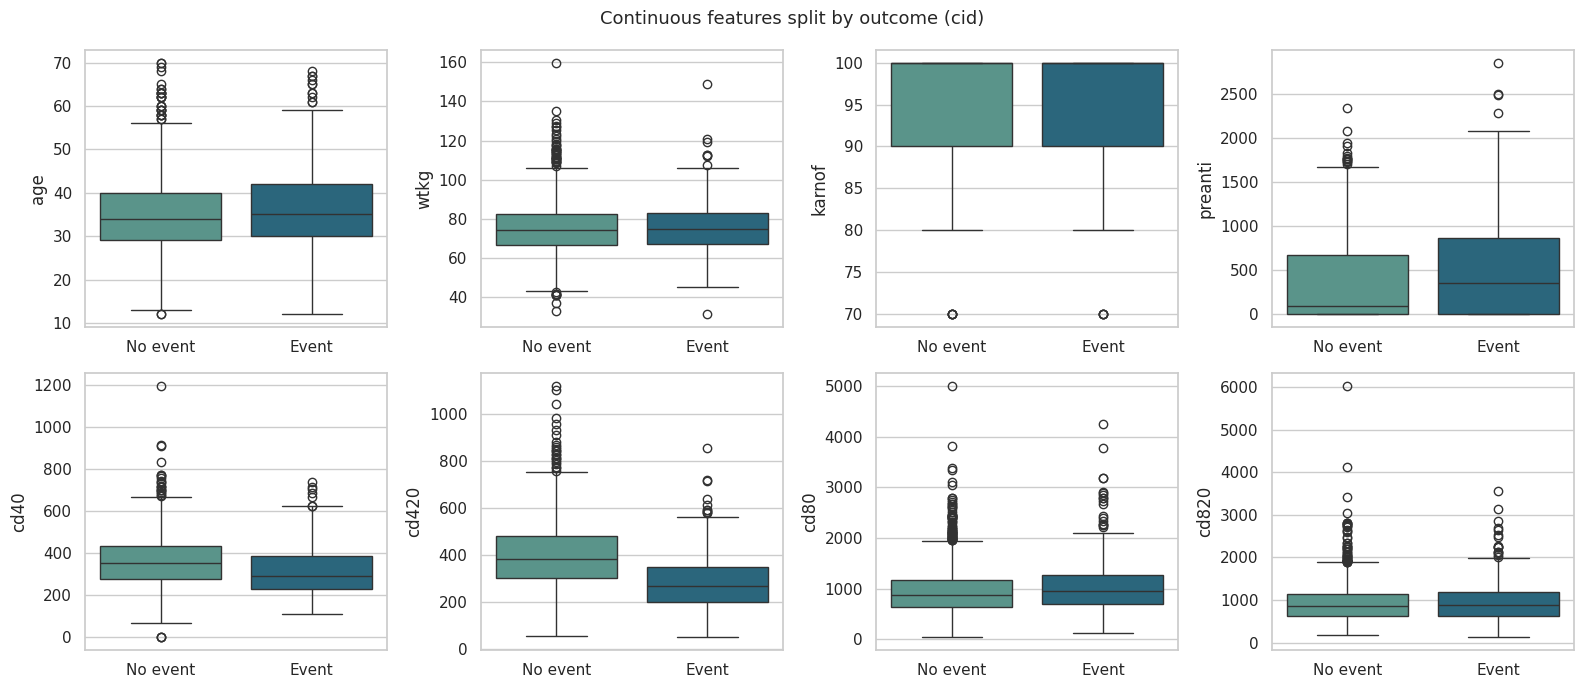

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, ev.CONTINUOUS_FEATURES):
    sns.boxplot(data=raw, x=ev.TARGET_COL, y=col, hue=ev.TARGET_COL, palette="crest", legend=False, ax=ax)
    ax.set_xticks([0, 1], ["No event", "Event"])
    ax.set_xlabel("")
fig.suptitle("Continuous features split by outcome (cid)", fontsize=13)
fig.tight_layout()
plt.show()

In [10]:
# Event rate (share of cid = 1) for each level of the binary / nominal features
event_rate = pd.DataFrame({col: raw.groupby(col)[ev.TARGET_COL].mean()
                           for col in ev.BINARY_FEATURES + ev.NOMINAL_FEATURES}).T
event_rate.columns = [f"level {c}" for c in event_rate.columns]
event_rate.round(3)

,level 0,level 1,level 2,level 3
hemo,0.245,0.228,NaN,NaN
homo,0.211,0.260,NaN,NaN
drugs,0.252,0.189,NaN,NaN
oprior,0.241,0.362,NaN,NaN
z30,0.184,0.292,NaN,NaN
race,0.259,0.206,NaN,NaN
gender,0.201,0.252,NaN,NaN
str2,0.181,0.288,NaN,NaN
symptom,0.218,0.365,NaN,NaN
treat,0.340,0.212,NaN,NaN


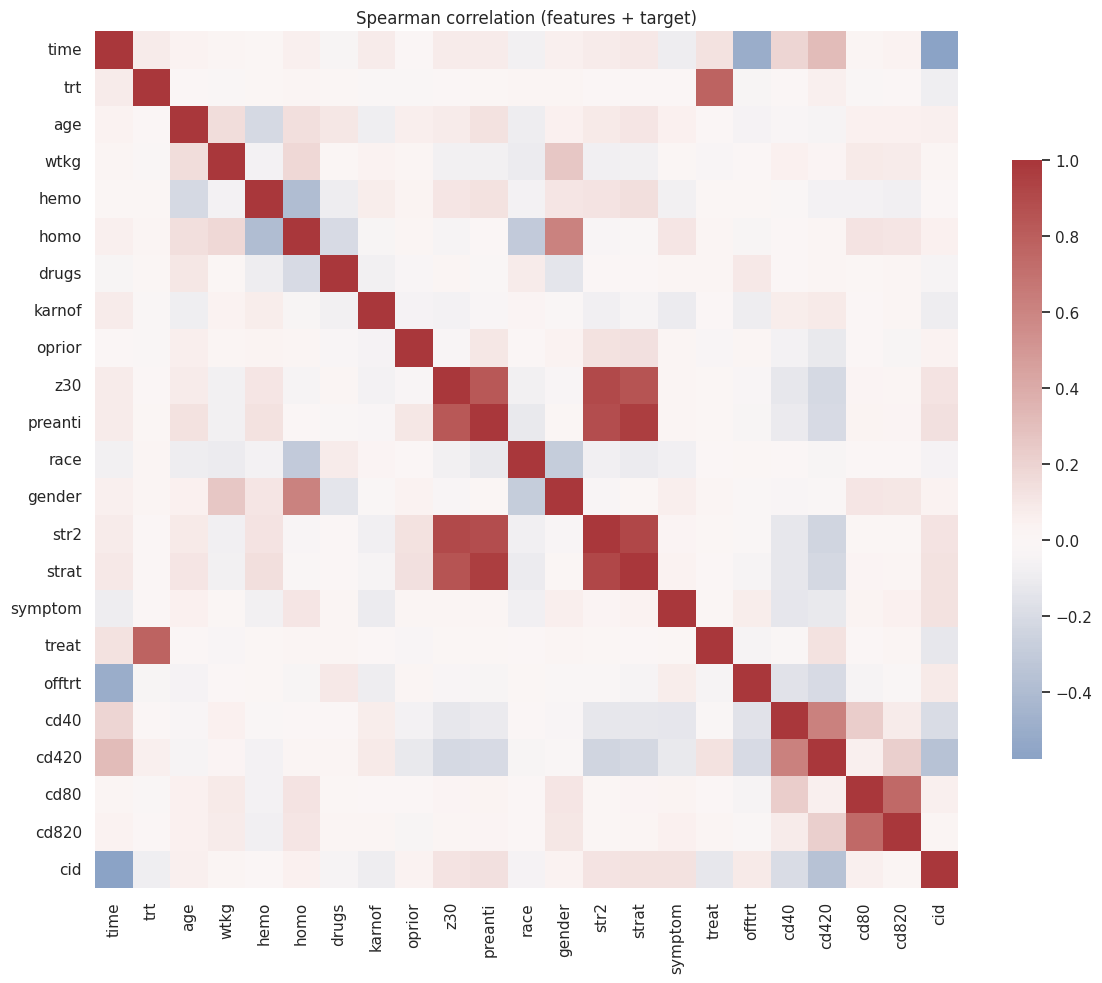

Strongest correlations with cid:
time       0.576
cd420      0.365
cd40       0.199
preanti    0.136
strat      0.131
treat      0.130


In [11]:
corr = raw.drop(columns=["pidnum", "zprior"]).corr(method="spearman")
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, cmap="vlag", center=0, ax=ax, cbar_kws={"shrink": 0.7})
ax.set_title("Spearman correlation (features + target)")
fig.tight_layout()
plt.show()
print("Strongest correlations with cid:")
print(corr[ev.TARGET_COL].drop(ev.TARGET_COL).abs().sort_values(ascending=False).head(6).round(3).to_string())

## 3. Cleaning decisions
These steps are deterministic and learn nothing from the data, so it is safe to apply them before the split.

| Column | Action | Reason |
|---|---|---|
| `pidnum` | drop | Patient identifier, carries no clinical signal |
| `time` | drop | Days until the event or censoring. It is only known *after* the outcome, so it leaks the answer |
| `zprior` | drop | Constant: every patient has the value 1 |

There are no missing values and no duplicate rows. The imputers inside the pipelines stay in place anyway, so that a test file with blank cells can still be scored.

In [13]:
time_auc = roc_auc_score(raw[ev.TARGET_COL], -raw["time"])
print(f"'time' on its own separates the classes with ROC-AUC = {time_auc:.3f} -> target leakage, dropped.")
print("'zprior' unique values:", raw["zprior"].unique())

data = raw.drop(columns=list(ev.DROPPED_COLUMNS)).drop_duplicates().reset_index(drop=True)
assert sorted(data.columns) == sorted(ev.FEATURE_COLUMNS + [ev.TARGET_COL])

n_features = len(ev.FEATURE_COLUMNS)
print(f"Clean table: {len(data)} rows x {n_features} input features + target")
assert n_features >= 12 and len(data) >= 500, "Assignment minimum (12 features, 500 rows) not met"
print("Assignment minimums satisfied: >= 12 features and >= 500 instances")

'time' on its own separates the classes with ROC-AUC = 0.888 -> target leakage, dropped.
'zprior' unique values: [1]
Clean table: 2139 rows x 21 input features + target
Assignment minimums satisfied: >= 12 features and >= 500 instances


## 4. Stratified train / test split
The split is 80 / 20 and stratified on `cid`, so both parts keep the same event rate. The seed is fixed at 5440.
The 20% test part is saved as **`test_data.csv`**: the original 21 feature columns plus `cid`, untransformed.
It is used **only** for the final evaluation below, and it is the file to upload to the Streamlit app.

In [15]:
X = data[ev.FEATURE_COLUMNS]
y = data[ev.TARGET_COL].astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED)

test_df = X_test.assign(**{ev.TARGET_COL: y_test}).reset_index(drop=True)
test_df.to_csv(ROOT / "test_data.csv", index=False)
print(f"test_data.csv written: {test_df.shape[0]} rows x {test_df.shape[1]} columns")

pd.DataFrame({"rows": [len(y_train), len(y_test)],
              "event share %": [y_train.mean() * 100, y_test.mean() * 100]},
             index=["train", "test"]).round(2)

test_data.csv written: 428 rows x 22 columns


,rows,event share %
train,1711,24.37
test,428,24.30


## 5. Preprocessing pipeline
Every model is a `Pipeline(preprocessor → classifier)`. The preprocessor is therefore fitted **only on training data**, including inside each cross-validation fold, so there is no leakage.
The saved file contains the fitted preprocessing too, which lets the app feed raw `test_data.csv` columns straight in.

| Group | Columns | Steps | Why |
|---|---|---|---|
| Continuous | age, wtkg, karnof, preanti, cd40, cd420, cd80, cd820 | median impute → standardise | KNN, SVM and Logistic Regression are sensitive to feature scale |
| Binary | hemo, homo, drugs, oprior, z30, race, gender, str2, symptom, treat, offtrt | most-frequent impute, kept as 0/1 | Already on a 0–1 scale |
| Nominal | trt (4 arms), strat (3 levels) | most-frequent impute → one-hot | The codes are categories, not quantities |

In [17]:
def make_preprocessor() -> ColumnTransformer:
    """Unfitted preprocessing; it is fitted inside each pipeline on training rows only."""
    continuous = Pipeline([("impute", SimpleImputer(strategy="median")),
                           ("scale", StandardScaler())])
    nominal = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([
        ("continuous", continuous, ev.CONTINUOUS_FEATURES),
        ("binary", SimpleImputer(strategy="most_frequent"), ev.BINARY_FEATURES),
        ("nominal", nominal, ev.NOMINAL_FEATURES),
    ])

make_preprocessor().fit(X_train).get_feature_names_out()

array(['continuous__age', 'continuous__wtkg', 'continuous__karnof',
       'continuous__preanti', 'continuous__cd40', 'continuous__cd420',
       'continuous__cd80', 'continuous__cd820', 'binary__hemo',
       'binary__homo', 'binary__drugs', 'binary__oprior', 'binary__z30',
       'binary__race', 'binary__gender', 'binary__str2',
       'binary__symptom', 'binary__treat', 'binary__offtrt',
       'nominal__trt_0', 'nominal__trt_1', 'nominal__trt_2',
       'nominal__trt_3', 'nominal__strat_1', 'nominal__strat_2',
       'nominal__strat_3'], dtype=object)

## 6. Models and hyper-parameter tuning
All five classifiers use the same preprocessing and the same 5-fold stratified cross-validation, run on the **training set only**.
The grid search picks the setting with the best mean **MCC** (the primary metric, because of the class imbalance); CV ROC-AUC is recorded alongside it.

* **Logistic Regression**: regularisation strength `C`, with and without class re-weighting.
* **Decision Tree**: depth, minimum leaf size, split criterion and class weighting, which control overfitting.
* **KNN**: number of neighbours, distance weighting, and Manhattan vs Euclidean distance.
* **Naive Bayes (Gaussian)**: the features are continuous and binary, not counts, so `GaussianNB` is the right variant. `MultinomialNB` would need non-negative count-like inputs. Only `var_smoothing` is tuned.
* **SVM (RBF kernel)**: `C`, `gamma` and class weighting. The grid search runs without probability estimates, for speed. The winning settings are then refitted with `probability=True` to get the class-1 probabilities that AUC needs. `SVC.predict` does not depend on that flag, so the predictions are unchanged (checked below).

In [19]:
mcc_scorer = make_scorer(matthews_corrcoef)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

candidates = {
    "Logistic Regression": (
        LogisticRegression(max_iter=5000, random_state=SEED),
        {"clf__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10], "clf__class_weight": [None, "balanced"]}),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=SEED),
        {"clf__max_depth": [2, 3, 4, 5, 6, 8, 10, None], "clf__min_samples_leaf": [1, 5, 10, 20, 40],
         "clf__criterion": ["gini", "entropy"], "clf__class_weight": [None, "balanced"]}),
    "KNN": (
        KNeighborsClassifier(),
        {"clf__n_neighbors": [3, 5, 7, 9, 11, 15, 21, 31, 41], "clf__weights": ["uniform", "distance"],
         "clf__p": [1, 2]}),
    "Naive Bayes": (
        GaussianNB(),
        {"clf__var_smoothing": list(np.logspace(-11, -3, 9))}),
    "Support Vector Machine": (
        SVC(kernel="rbf", random_state=SEED),
        {"clf__C": [0.1, 0.3, 1, 3, 10], "clf__gamma": ["scale", 0.003, 0.01, 0.03, 0.1],
         "clf__class_weight": [None, "balanced"]}),
}

fitted, cv_rows, searches = {}, [], {}
for name, (estimator, grid) in candidates.items():
    search = GridSearchCV(Pipeline([("prep", make_preprocessor()), ("clf", estimator)]), grid,
                          scoring={"mcc": mcc_scorer, "roc_auc": "roc_auc"}, refit="mcc",
                          cv=cv, n_jobs=-1)
    started = time.perf_counter()
    search.fit(X_train, y_train)
    search_secs = time.perf_counter() - started
    best, refit_secs = search.best_estimator_, search.refit_time_

    if name == "Support Vector Machine":
        tuned = best
        best = Pipeline([("prep", make_preprocessor()),
                         ("clf", SVC(kernel="rbf", probability=True, random_state=SEED))])
        best.set_params(**search.best_params_)
        started = time.perf_counter()
        best.fit(X_train, y_train)
        refit_secs = time.perf_counter() - started
        assert (best.predict(X_train) == tuned.predict(X_train)).all(), "SVC predictions changed"

    fitted[name] = best
    searches[name] = search
    i = search.best_index_
    cv_rows.append({
        "ML Model Name": name,
        "settings tried": len(search.cv_results_["params"]),
        "best params": {k.replace("clf__", ""): v for k, v in search.best_params_.items()},
        "CV MCC mean": search.cv_results_["mean_test_mcc"][i],
        "CV MCC std": search.cv_results_["std_test_mcc"][i],
        "CV AUC mean": search.cv_results_["mean_test_roc_auc"][i],
        "search secs": search_secs,
        "final fit secs": refit_secs,
    })

cv_summary = pd.DataFrame(cv_rows).set_index("ML Model Name")
cv_summary.to_csv(RESULTS_DIR / "cv_summary.csv")
cv_summary.round(4)

,settings tried,best params,CV MCC mean,CV MCC std,CV AUC mean,search secs,final fit secs
ML Model Name,,,,,,,
Logistic Regression,14,"{'C': 3, 'class_weight': 'balanced'}",0.3554,0.0355,0.7611,6.6781,0.3792
Decision Tree,160,"{'class_weight': 'balanced', 'criterion': 'gin...",0.3660,0.0433,0.7274,22.8379,0.0354
KNN,36,"{'n_neighbors': 11, 'p': 1, 'weights': 'distan...",0.2312,0.0278,0.6797,6.3576,0.0346
Naive Bayes,9,{'var_smoothing': 1e-11},0.3186,0.0447,0.7266,1.2331,0.0375
Support Vector Machine,50,"{'C': 1, 'class_weight': 'balanced', 'gamma': ...",0.3604,0.0381,0.7594,24.5111,1.1325


## 7. Evaluation on the held-out test set
All six assignment metrics come from `actg_eval.score_predictions`, the same function the app calls.
Precision, Recall and F1 are reported for the **event class (cid = 1)**. AUC uses the predicted probability of class 1.
Training-set scores are computed too, to show over- or under-fitting.

In [21]:
test_rows, train_rows, preds = [], [], {}
for name, model in fitted.items():
    started = time.perf_counter()
    test_metrics, y_pred, y_score = ev.evaluate_model(model, X_test, y_test)
    predict_ms = (time.perf_counter() - started) * 1000
    train_metrics, _, _ = ev.evaluate_model(model, X_train, y_train)
    preds[name] = (y_pred, y_score)
    test_rows.append({"ML Model Name": name, **test_metrics})
    train_rows.append({"ML Model Name": name, **train_metrics, "test predict ms": predict_ms})

metrics_test = pd.DataFrame(test_rows).set_index("ML Model Name")[ev.METRIC_NAMES]
metrics_train = pd.DataFrame(train_rows).set_index("ML Model Name")
metrics_test.to_csv(RESULTS_DIR / "metrics_comparison.csv")
metrics_train.to_csv(RESULTS_DIR / "train_metrics.csv")

table_md = ["| ML Model Name | " + " | ".join(ev.METRIC_NAMES) + " |",
            "|---|" + "---|" * len(ev.METRIC_NAMES)]
table_md += [f"| {n} | " + " | ".join(f"{metrics_test.loc[n, m]:.4f}" for m in ev.METRIC_NAMES) + " |"
             for n in metrics_test.index]
(RESULTS_DIR / "metrics_comparison.md").write_text("\n".join(table_md) + "\n", encoding="utf-8")

print("Test-set metrics (held-out 20%):")
metrics_test.round(4)

Test-set metrics (held-out 20%):


,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.6706,0.7532,0.4011,0.7212,0.5155,0.3247
Decision Tree,0.7266,0.6983,0.4435,0.4904,0.4658,0.2833
KNN,0.7593,0.6029,0.5217,0.1154,0.1890,0.1549
Naive Bayes,0.6846,0.6693,0.3719,0.4327,0.4000,0.1887
Support Vector Machine,0.6729,0.7301,0.3953,0.6538,0.4928,0.2912


In [22]:
# Over-fitting check: training score minus test score (large positive gap = memorising)
(metrics_train[ev.METRIC_NAMES] - metrics_test).round(4).add_suffix(" gap")

,Accuracy gap,AUC gap,Precision gap,Recall gap,F1 gap,MCC gap
ML Model Name,,,,,,
Logistic Regression,0.0308,0.0243,0.0325,0.0151,0.0303,0.0470
Decision Tree,0.0343,0.0390,0.0653,0.0660,0.0657,0.0888
KNN,0.2407,0.3971,0.4783,0.8846,0.8110,0.8451
Naive Bayes,0.0594,0.0674,0.1049,0.0853,0.0966,0.1371
Support Vector Machine,0.0723,0.0842,0.0896,0.0800,0.0912,0.1383


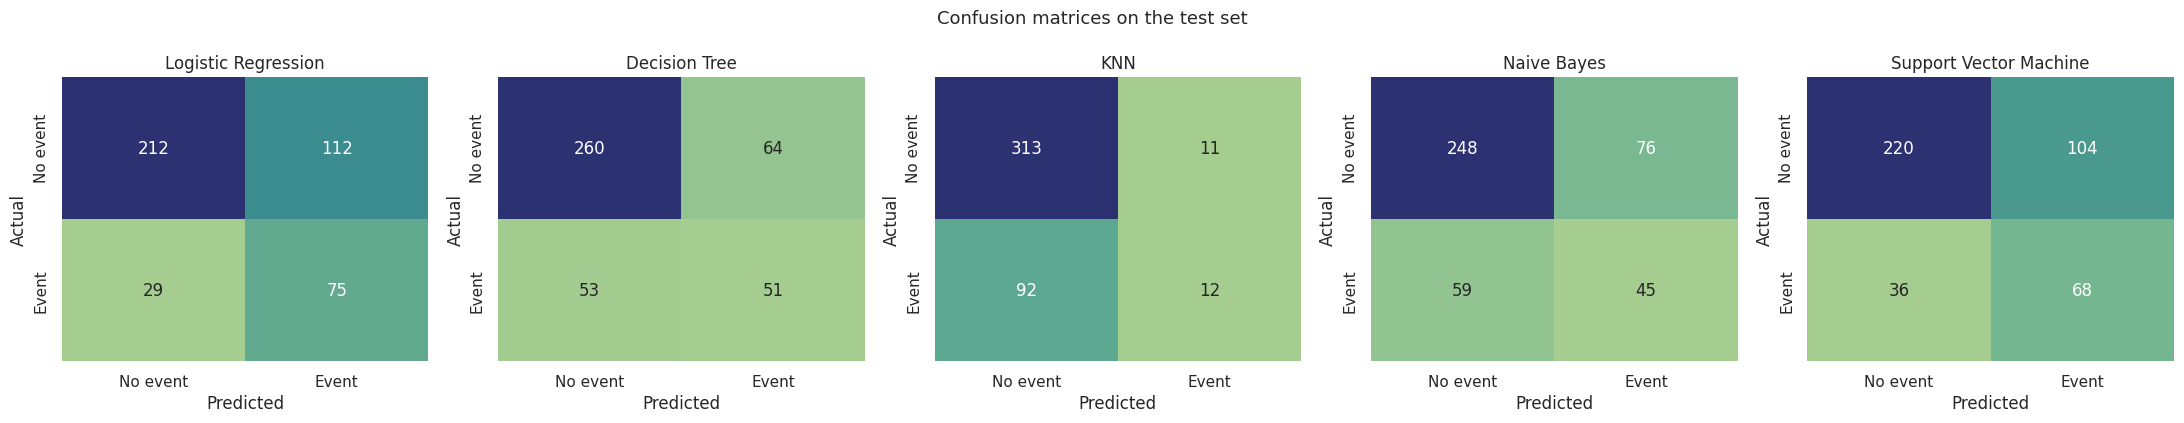

In [23]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4.3))
confusions = {}
for ax, (name, (y_pred, _)) in zip(axes, preds.items()):
    cm = ev.confusion_frame(y_test, y_pred)
    confusions[name] = cm.values.tolist()
    sns.heatmap(cm.values, annot=True, fmt="d", cmap="crest", cbar=False, ax=ax,
                xticklabels=["No event", "Event"], yticklabels=["No event", "Event"])
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
fig.suptitle("Confusion matrices on the test set", fontsize=13)
fig.tight_layout()
plt.show()
_ = (RESULTS_DIR / "confusion_matrices.json").write_text(json.dumps(confusions, indent=2), encoding="utf-8")

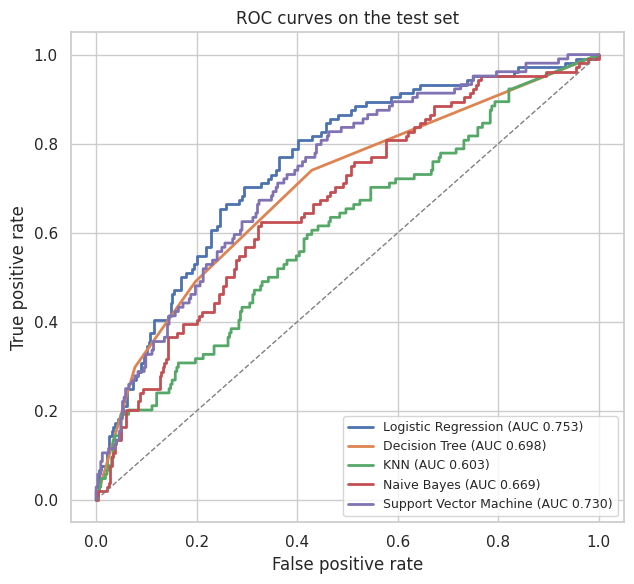

In [24]:
fig, ax = plt.subplots(figsize=(6.5, 6))
for name, (_, y_score) in preds.items():
    fpr, tpr, _ = roc_curve(y_test, y_score)
    ax.plot(fpr, tpr, lw=2, label=f"{name} (AUC {roc_auc_score(y_test, y_score):.3f})")
ax.plot([0, 1], [0, 1], "--", color="grey", lw=1)
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC curves on the test set")
ax.legend(loc="lower right", fontsize=9)
fig.tight_layout()
plt.show()

In [25]:
for name, (y_pred, _) in preds.items():
    print(f"\n=== {name} ===")
    print(ev.report_frame(y_test, y_pred).round(4).to_string())


=== Logistic Regression ===
                     precision  recall  f1-score  support
No event (censored)     0.8797  0.6543    0.7504      324
AIDS event / death      0.4011  0.7212    0.5155      104
accuracy                   NaN     NaN    0.6706      428
macro avg               0.6404  0.6877    0.6330      428
weighted avg            0.7634  0.6706    0.6933      428

=== Decision Tree ===
                     precision  recall  f1-score  support
No event (censored)     0.8307  0.8025    0.8163      324
AIDS event / death      0.4435  0.4904    0.4658      104
accuracy                   NaN     NaN    0.7266      428
macro avg               0.6371  0.6464    0.6410      428
weighted avg            0.7366  0.7266    0.7311      428

=== KNN ===
                     precision  recall  f1-score  support
No event (censored)     0.7728  0.9660    0.8587      324
AIDS event / death      0.5217  0.1154    0.1890      104
accuracy                   NaN     NaN    0.7593      428
macro a

## 7b. What the models learned
These facts back up the observations in the README. Nothing here changes the saved models.
The unweighted Logistic Regression below is a comparison only: it is not saved and plays no part in choosing the winner.

In [27]:
from sklearn.base import clone

# Logistic Regression: largest coefficients on the transformed inputs (+ raises P(event))
lr = fitted["Logistic Regression"]
short_names = [n.split("__", 1)[1] for n in lr.named_steps["prep"].get_feature_names_out()]
coef = pd.Series(lr.named_steps["clf"].coef_[0], index=short_names)
print("Logistic Regression, largest coefficients:")
print(coef.reindex(coef.abs().sort_values(ascending=False).index).head(6).round(3).to_string())

# Effect of class weighting: same C, trained on the training rows only
unweighted = clone(lr).set_params(clf__class_weight=None).fit(X_train, y_train)
unweighted_metrics, unweighted_pred, _ = ev.evaluate_model(unweighted, X_test, y_test)
print("\nLogistic Regression without class weights:")
print({m: round(float(v), 4) for m, v in unweighted_metrics.items()},
      "| predicted events:", int(unweighted_pred.sum()))

Logistic Regression, largest coefficients:
cd420     -1.093
drugs     -0.425
symptom    0.404
hemo      -0.362
treat     -0.314
z30        0.269

Logistic Regression without class weights:
{'Accuracy': 0.7687, 'AUC': 0.754, 'Precision': 0.551, 'Recall': 0.2596, 'F1': 0.3529, 'MCC': 0.2582} | predicted events: 49


In [28]:
# Decision Tree: what the saved tree actually uses, and how CV score changed with depth
dt = fitted["Decision Tree"]
tree = dt.named_steps["clf"].tree_
used = sorted({short_names[f] for f in tree.feature if f >= 0})
print("Decision Tree features used:", used, "| leaves:", dt.named_steps["clf"].get_n_leaves())
print("Distinct P(event) values on the test set:", np.unique(ev.positive_scores(dt, X_test).round(6)).size)
if used == ["cd420"]:
    scaler = dt.named_steps["prep"].named_transformers_["continuous"].named_steps["scale"]
    i = ev.CONTINUOUS_FEATURES.index("cd420")
    cutoff = scaler.mean_[i] + tree.threshold[0] * scaler.scale_[i]
    same = bool((dt.predict(X_test) == (X_test["cd420"] <= cutoff).astype(int).to_numpy()).all())
    print(f"Root split in real units: cd420 <= {cutoff:.1f} cells/mm3 | predictions identical to that one rule: {same}")

dt_cv = pd.DataFrame(searches["Decision Tree"].cv_results_)
dt_cv["depth"] = [str(p["clf__max_depth"]) for p in dt_cv["params"]]
print("\nBest CV MCC at each max_depth:")
print(dt_cv.groupby("depth")["mean_test_mcc"].max().reindex(["2", "3", "4", "5", "6", "8", "10", "None"]).round(4).to_string())

Decision Tree features used: ['cd420'] | leaves: 4
Distinct P(event) values on the test set: 4
Root split in real units: cd420 <= 273.5 cells/mm3 | predictions identical to that one rule: True

Best CV MCC at each max_depth:
depth
2       0.3660
3       0.3358
4       0.3319
5       0.3391
6       0.3351
8       0.3351
10      0.3351
None    0.3351


In [29]:
# Naive Bayes: tuning effect, and how far the independence assumption is from the data
nb_cv = pd.DataFrame(searches["Naive Bayes"].cv_results_)
print("Naive Bayes, CV MCC for each var_smoothing:")
print(pd.Series(nb_cv["mean_test_mcc"].values,
                index=[f"{p['clf__var_smoothing']:.0e}" for p in nb_cv["params"]]).round(4).to_string())

spearman = data.corr(method="spearman")
print("\nSpearman correlation between related features:")
for a, b in [("cd40", "cd420"), ("cd80", "cd820"), ("trt", "treat"), ("str2", "strat"), ("str2", "preanti")]:
    print(f"  {a:6s} ~ {b:8s} {spearman.loc[a, b]:+.3f}")

# KNN: how few events it predicts, and whether any k would have helped
knn_cv = pd.DataFrame(searches["KNN"].cv_results_)
knn_cv["k"] = [p["clf__n_neighbors"] for p in knn_cv["params"]]
print("\nKNN predicted events on the test set:", int(preds["KNN"][0].sum()), "of", len(y_test))
print("Best CV MCC at each k:")
print(knn_cv.groupby("k")["mean_test_mcc"].max().round(4).to_string())

print("\nAlways predicting 'no event' would score Accuracy", round(float((y_test == 0).mean()), 4), "on this test set.")

Naive Bayes, CV MCC for each var_smoothing:
1e-11    0.3186
1e-10    0.3186
1e-09    0.3186
1e-08    0.3186
1e-07    0.3186
1e-06    0.3186
1e-05    0.3186
1e-04    0.3186
1e-03    0.3167

Spearman correlation between related features:
  cd40   ~ cd420    +0.620
  cd80   ~ cd820    +0.742
  trt    ~ treat    +0.773
  str2   ~ strat    +0.920
  str2   ~ preanti  +0.884

KNN predicted events on the test set: 23 of 428
Best CV MCC at each k:
k
3     0.2044
5     0.2269
7     0.2216
9     0.2150
11    0.2312
15    0.2255
21    0.2268
31    0.1928
41    0.2045

Always predicting 'no event' would score Accuracy 0.757 on this test set.


## 8. Save the trained pipelines
Each file in `model/` is a complete fitted pipeline (preprocessing + classifier), compressed with joblib.
`model/model_card.json` records the schema, metric convention, split, seed, library versions, the chosen hyper-parameters and the test metrics.

In [31]:
card = {
    "project": "ACTG 175 - prediction of an AIDS-defining event or death (cid)",
    "dataset": {"name": "AIDS Clinical Trials Group Study 175",
                "source": "https://archive.ics.uci.edu/dataset/890/aids+clinical+trials+group+study+175",
                "rows_raw": int(len(raw)), "rows_used": int(len(data))},
    "target": ev.TARGET_COL,
    "positive_class": ev.POSITIVE_CLASS,
    "class_labels": {str(k): v for k, v in ev.CLASS_LABELS.items()},
    "feature_order": ev.FEATURE_COLUMNS,
    "feature_groups": {"continuous": ev.CONTINUOUS_FEATURES, "binary": ev.BINARY_FEATURES,
                       "nominal": ev.NOMINAL_FEATURES},
    "dropped_columns": ev.DROPPED_COLUMNS,
    "metric_convention": ev.METRIC_CONVENTION,
    "split": {"test_size": TEST_SIZE, "stratified": True, "seed": SEED,
              "train_rows": int(len(y_train)), "test_rows": int(len(y_test))},
    "tuning": {"cv": "StratifiedKFold(n_splits=5, shuffle=True)", "refit_metric": "MCC"},
    "versions": {"python": platform.python_version(), "scikit-learn": sklearn.__version__,
                 "numpy": np.__version__, "pandas": pd.__version__, "joblib": joblib.__version__},
    "models": {},
}
for name, model in fitted.items():
    joblib.dump(model, MODEL_DIR / ev.MODEL_REGISTRY[name], compress=3)
    card["models"][name] = {
        "file": ev.MODEL_REGISTRY[name],
        "estimator": type(model.named_steps["clf"]).__name__,
        "best_params": cv_summary.loc[name, "best params"],
        "cv_mcc_mean": round(float(cv_summary.loc[name, "CV MCC mean"]), 4),
        "test_metrics": {m: round(float(metrics_test.loc[name, m]), 6) for m in ev.METRIC_NAMES},
    }
(MODEL_DIR / "model_card.json").write_text(json.dumps(card, indent=2, default=str), encoding="utf-8")

pd.Series({f.name: f"{f.stat().st_size / 1024:.1f} KB" for f in sorted(MODEL_DIR.iterdir())}, name="size")

.gitkeep                       0.0 KB
decision_tree.joblib           2.6 KB
knn.joblib                    90.2 KB
logistic_regression.joblib     2.4 KB
model_card.json                4.0 KB
naive_bayes.joblib             2.9 KB
svm.joblib                    67.3 KB
Name: size, dtype: object

## 9. Final comparison
This cell prints a run banner (who, when, on which machine, with which library versions) and then the final test-set table.
**Screenshot this output on the BITS Virtual Lab** as the proof of execution required by the assignment.

In [33]:
banner = [
    "ML Assignment 2 | ACTG 175 classification (5 models x 6 metrics)",
    "Student : Mani Rathinam Subbaiah | BITS ID 2026AJ05440",
    f"Run at  : {datetime.now():%d-%b-%Y %H:%M:%S}",
    f"Host    : {socket.gethostname()} | user: {getpass.getuser()} | {platform.system()} {platform.release()}",
    f"Python  : {platform.python_version()} | scikit-learn {sklearn.__version__}",
    f"Data    : {len(data)} patients, {len(ev.FEATURE_COLUMNS)} features | train {len(y_train)} / test {len(y_test)} | seed {SEED}",
]
width = max(map(len, banner)) + 4
print("=" * width)
for line in banner:
    print("  " + line)
print("=" * width)
print(metrics_test.round(4).to_string())
leader = metrics_test["MCC"].idxmax()
print(f"\nHighest test MCC: {leader} ({metrics_test.loc[leader, 'MCC']:.4f})")

  ML Assignment 2 | ACTG 175 classification (5 models x 6 metrics)
  Student : Mani Rathinam Subbaiah | BITS ID 2026AJ05440
  Run at  : 08-Nov-2026 15:20:12
  Host    : ip-10-3-22-66.ap-south-1.compute.internal | user: s2026aj05440 | Linux 5.14.0-503.14.1.el9_5.x86_64
  Python  : 3.12.7 | scikit-learn 1.7.2
  Data    : 2139 patients, 21 features | train 1711 / test 428 | seed 5440
                        Accuracy     AUC  Precision  Recall      F1     MCC
ML Model Name                                                              
Logistic Regression       0.6706  0.7532     0.4011  0.7212  0.5155  0.3247
Decision Tree             0.7266  0.6983     0.4435  0.4904  0.4658  0.2833
KNN                       0.7593  0.6029     0.5217  0.1154  0.1890  0.1549
Naive Bayes               0.6846  0.6693     0.3719  0.4327  0.4000  0.1887
Support Vector Machine    0.6729  0.7301     0.3953  0.6538  0.4928  0.2912

Highest test MCC: Logistic Regression (0.3247)
